# 06 — Read order flow: how the book changes

**Question:** Are standing liquidity, liquidity changes and executed flow telling
the same story?

**By the end:** compute top-level imbalance and event-based OFI, distinguish them
from signed trade volume, and form a testable forward-movement hypothesis.
**Time:** 35–45 minutes. **Inputs:** outcome-book updates, Binance trades and
connection events. This is exploratory analysis of one window, not a fitted signal.

In [1]:
import sys
from pathlib import Path

# Works when Jupyter starts at the repository root or in the notebook folder.
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    finish_plot,
    observed_ofi_grid,
    plot_style,
    strict_forward_move,
    trade_frame,
)
from tyrex_pm.research.tuto_btc5m.data import Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. A stock, a flow and an execution

- **Standing imbalance:** more displayed shares at the best bid or best ask now.
- **Order-flow imbalance (OFI):** signed changes at those best prices through time.
- **Signed trade flow:** executed quantities with an explicitly supported direction.

A bid can be large but shrinking. Another can be smaller but replenished after
every trade. These states can have different dynamics despite similar prices.
Aggregated updates do not reveal individual cancellations or private queue orders.
See the [public market-channel contract](https://docs.polymarket.com/api-reference/wss/market).

In [2]:
study = BookStudy(sample)
grid = study.grid()
iid = next(i for i, label in sample.labels.items() if str(label).lower() == "up")
up = grid[grid.instrument_id == iid].reset_index(drop=True)
events = study.tape[
    (study.tape.instrument_id == iid)
    & (study.tape.received_at >= pd.Timestamp(sample.start, tz="UTC"))
    & (study.tape.received_at < pd.Timestamp(sample.end, tz="UTC"))
].copy()
display(
    events[
        ["received_at", "bid", "ask", "bid_quantity", "ask_quantity", "imbalance", "ofi", "valid"]
    ].head(10)
)

,received_at,bid,ask,bid_quantity,ask_quantity,imbalance,ofi,valid
2,2026-10-01 15:45:00.005732300+00:00,0.64,0.65,5.0,180.80,-0.946179,0.00,True
4,2026-10-01 15:45:00.056243100+00:00,0.64,0.65,5.0,180.80,-0.946179,0.00,True
6,2026-10-01 15:45:00.056243100+00:00,0.64,0.65,5.0,190.80,-0.948927,-10.00,True
8,2026-10-01 15:45:00.056243100+00:00,0.64,0.65,5.0,190.80,-0.948927,0.00,True
10,2026-10-01 15:45:00.082258900+00:00,0.64,0.65,5.0,188.49,-0.948318,2.31,True
12,2026-10-01 15:45:00.095770500+00:00,0.64,0.65,5.0,188.49,-0.948318,NaN,True
14,2026-10-01 15:45:00.130296800+00:00,0.64,0.65,5.0,188.49,-0.948318,0.00,True
16,2026-10-01 15:45:00.144814200+00:00,0.64,0.65,5.0,188.49,-0.948318,0.00,True
18,2026-10-01 15:45:00.144814200+00:00,0.64,0.65,5.0,188.49,-0.948318,0.00,True
20,2026-10-01 15:45:00.144814200+00:00,0.64,0.65,5.0,188.49,-0.948318,0.00,True


## 2. Standing imbalance is a ratio

$I=(Q_b-Q_a)/(Q_b+Q_a)$ lies between −1 and +1 when both quantities are positive.
It measures displayed top-level balance, not a probability of Up winning. A single
large order can change it without any execution.

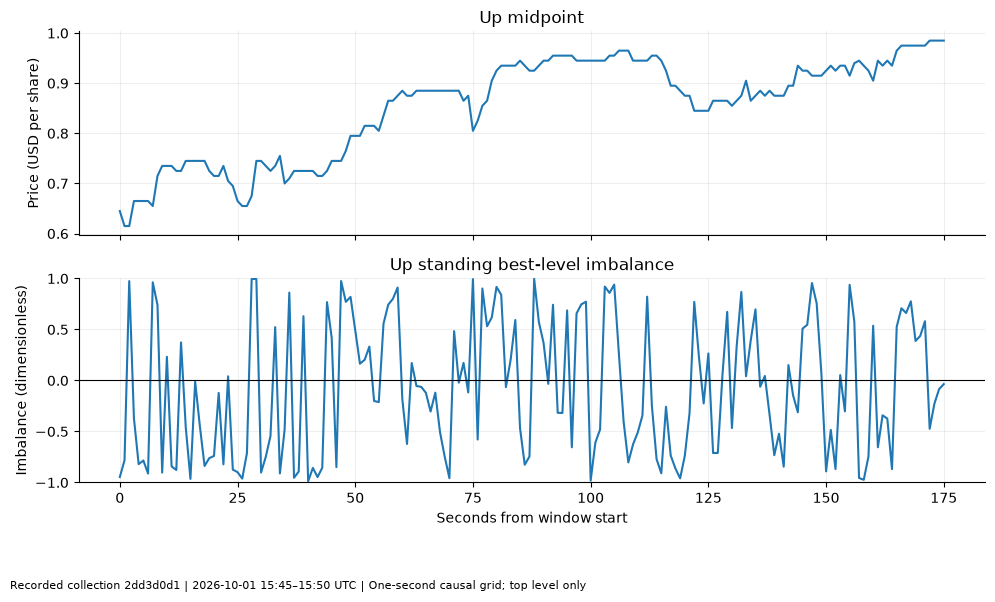

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x = (up.time - pd.Timestamp(sample.start, tz="UTC")).dt.total_seconds()
axes[0].plot(x, up.mid)
axes[0].set(title="Up midpoint", ylabel="Price (USD per share)")
axes[1].plot(x, up.imbalance)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(
    title="Up standing best-level imbalance",
    xlabel="Seconds from window start",
    ylabel="Imbalance (dimensionless)",
    ylim=(-1, 1),
)
finish_plot(fig, sample, "One-second causal grid; top level only")

## 3. Event-based OFI: additions and removals at the best prices

At the same bid, increasing bid quantity contributes positively. If the bid
improves, its new quantity contributes positively; if it retreats, the old
quantity contributes negatively. Ask contributions have the opposite sign.
The shared helper implements this price-and-quantity rule.

OFI resets across snapshots, unusable states and selected socket epochs. A
snapshot is not a new wave of orders merely because it contains large quantities.
The measure is inspired by [Cont, Kukanov and Stoikov](https://arxiv.org/abs/1011.6402),
whose empirical setting was equities. Its usefulness here is a hypothesis.

The one-second plot sums only increments actually observed inside valid seed
epochs. Changes introduced by a new snapshot are excluded, so this is a
**partial observed-flow measure**, not the complete venue OFI. Bins with
unusable states or socket changes remain missing. Frequent snapshots can
remove information from this measurement; they are not evidence of zero flow.

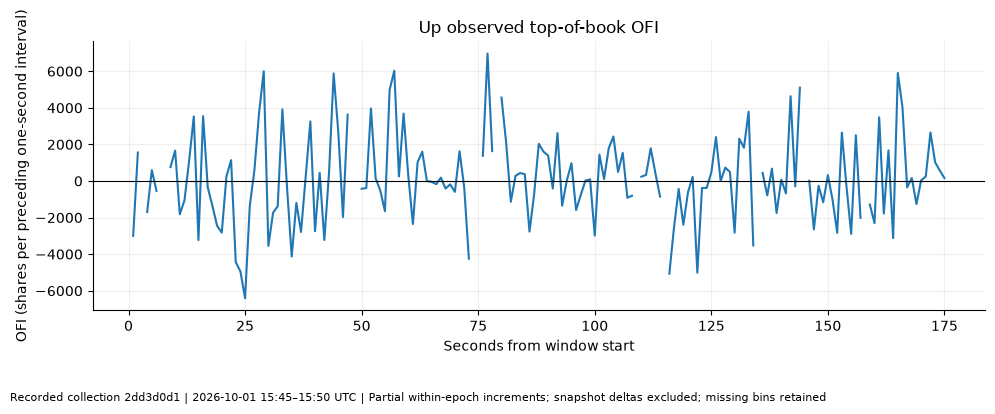

,time,imbalance,observed_ofi_shares,analysis_eligible
0,2026-10-01 15:45:00+00:00,-0.946179,NaN,True
1,2026-10-01 15:45:01+00:00,-0.782609,-3002.82,True
2,2026-10-01 15:45:02+00:00,0.974640,1555.11,True
3,2026-10-01 15:45:03+00:00,-0.371341,NaN,True
4,2026-10-01 15:45:04+00:00,-0.819971,-1696.68,True
5,2026-10-01 15:45:05+00:00,-0.784268,591.07,True
6,2026-10-01 15:45:06+00:00,-0.912399,-542.07,True
7,2026-10-01 15:45:07+00:00,0.962269,NaN,True
8,2026-10-01 15:45:08+00:00,0.741396,NaN,True
9,2026-10-01 15:45:09+00:00,-0.903100,757.36,True


In [4]:
# Use only increments observed in (t-1 second, t].
# Snapshot deltas are excluded; invalid states/socket changes suppress a bin.
up["observed_ofi_shares"] = observed_ofi_grid(events, up)
fig, ax = plt.subplots()
ax.plot(x, up.observed_ofi_shares)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title="Up observed top-of-book OFI",
    xlabel="Seconds from window start",
    ylabel="OFI (shares per preceding one-second interval)",
)
finish_plot(
    fig, sample, "Partial within-epoch increments; snapshot deltas excluded; missing bins retained"
)
display(up[["time", "imbalance", "observed_ofi_shares", "analysis_eligible"]].head(10))

## 4. Deeper changes: displayed additions and decreases

For an observed level, `new_quantity − previous_quantity` measures its displayed
change inside a valid selected socket epoch. Positive changes add displayed size;
negative changes remove it. This decomposition does not classify removals as
cancelled orders, fills, or intent. Coalesced/repeated updates also limit interpretation.

,added,decreased
Book side,,
BUY,1437956.89,1528157.22
SELL,1127396.04,1271821.53


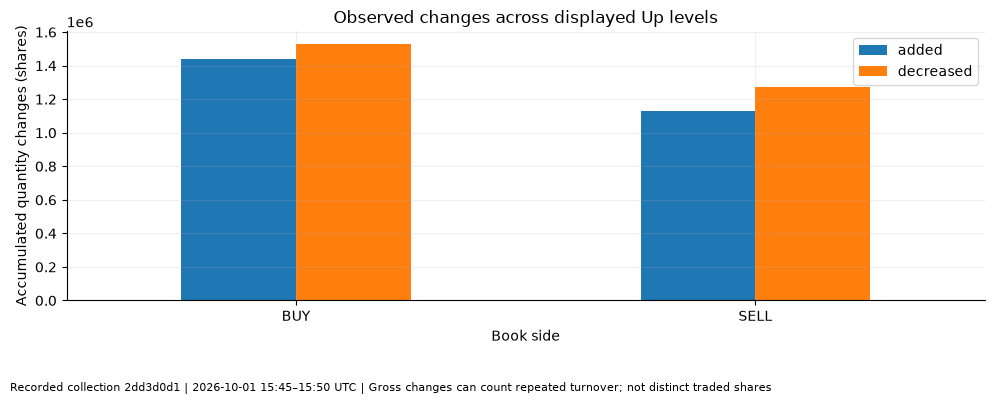

In [5]:
changes = study.level_changes
changes = changes[
    (changes.instrument_id == iid)
    & (changes.received_at >= pd.Timestamp(sample.start, tz="UTC"))
    & (changes.received_at < pd.Timestamp(sample.end, tz="UTC"))
].copy()
if not changes.empty:
    changes["added"] = changes.quantity_change.clip(lower=0)
    changes["decreased"] = -changes.quantity_change.clip(upper=0)
    amounts = changes.groupby("side")[["added", "decreased"]].sum()
    display(amounts.rename_axis("Book side"))
    fig, ax = plt.subplots()
    amounts.plot.bar(ax=ax, rot=0)
    ax.set(
        title="Observed changes across displayed Up levels",
        xlabel="Book side",
        ylabel="Accumulated quantity changes (shares)",
    )
    finish_plot(
        fig, sample, "Gross changes can count repeated turnover; not distinct traded shares"
    )
else:
    display(Markdown("No eligible selected-stream level changes are available."))

## 5. Executed flow: use a supported sign convention

For Binance's trade message, `buyer_is_maker=True` means the seller was the
aggressor; `False` means the buyer was. We use that documented convention only
where the flag is present. See [Binance trade-stream documentation](https://developers.binance.com/docs/binance-spot-api-docs/web-socket-streams).

BTC flow is measured in BTC; outcome-book OFI is measured in shares. They cannot
be summed as though they had the same units. Polymarket's reported trade side is
shown separately without assuming an unqualified historical aggressor mapping.

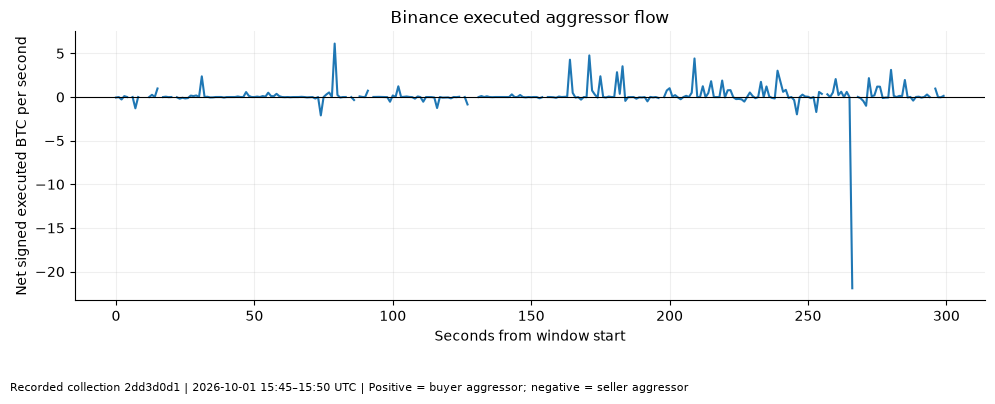

reported_side
BUY     754
SELL    109
Name: Reported PM trade rows, dtype: int64

In [6]:
btc_trades = trade_frame(sample)
btc_trades["aggressor_sign"] = btc_trades.buyer_is_maker.map({True: -1, False: 1})
btc_trades["signed_BTC"] = btc_trades.quantity_float * btc_trades.aggressor_sign
flow = btc_trades.set_index("time").signed_BTC.resample("1s").sum(min_count=1)
fig, ax = plt.subplots()
ax.plot((flow.index - pd.Timestamp(sample.start, tz="UTC")).total_seconds(), flow.values)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    title="Binance executed aggressor flow",
    xlabel="Seconds from window start",
    ylabel="Net signed executed BTC per second",
)
finish_plot(fig, sample, "Positive = buyer aggressor; negative = seller aggressor")
pm_trades = sample.frame("trade_prints")
pm_trades = pm_trades[pm_trades.source_id == "clob"]
display(pm_trades.groupby("reported_side", dropna=False).size().rename("Reported PM trade rows"))

## 6. First research question: does imbalance precede movement?

We compare current standing imbalance with the midpoint five seconds later.
There are two sensible but different eligibility questions:

1. **Same seed:** require the entire interval to stay inside one reconstructed seed
   epoch. This is very restrictive when full snapshots arrive frequently.
2. **Same socket with fresh snapshots:** allow a fresh usable snapshot to provide
   a later price on the same connected session/socket. Snapshot size differences
   still do not become order-flow increments.

The table below reports both. The plot uses the second interpretation. It requires
eligible grid points and excludes recorded unusable states, including sub-second
ones, and socket/session changes. Unsequenced provider completeness remains unknown.
The final five seconds have no target and are never filled with zero.

This is a **forward diagnostic**, not model training. Five-second targets overlap,
and one window is a tiny research unit. No p-value, train/test score or profitability
claim is justified here.

same_seed_comparisons              0
fresh_same_socket_comparisons    122
dtype: int64

,imbalance,observed_ofi_shares,next_5s_move_cents
count,176.000000,162.000000,122.000000
mean,-0.075654,124.205062,0.692623
std,0.651522,2399.508208,2.914375
min,-0.987903,-6411.340000,-8.000000
25%,-0.736002,-1282.282500,-1.000000
50%,-0.120978,55.530000,1.000000
75%,0.548752,1513.300000,2.000000
max,0.997289,6965.920000,8.000000


Eligible forward comparisons: 122 ; independent market windows: 1


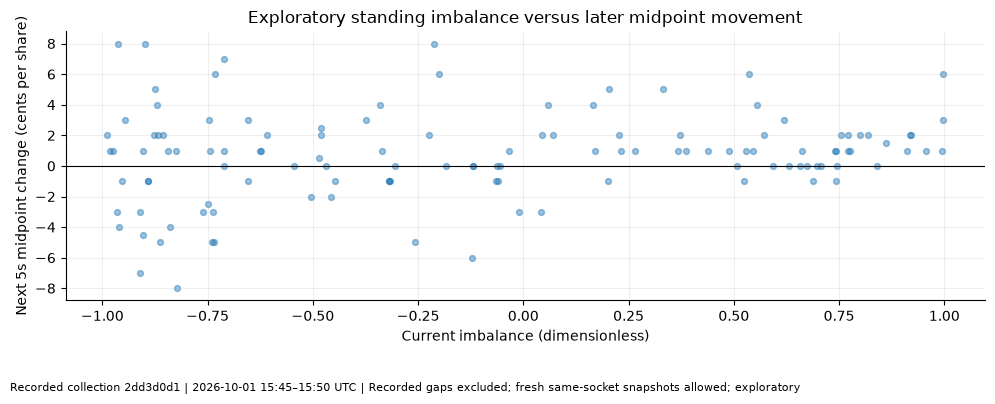

In [7]:
same_seed = strict_forward_move(up, 5, events=events)
same_socket = strict_forward_move(up, 5, events=events, require_same_seed=False)
display(
    pd.Series(
        {
            "same_seed_comparisons": same_seed.notna().sum(),
            "fresh_same_socket_comparisons": same_socket.notna().sum(),
        }
    )
)
up["next_5s_move_cents"] = same_socket * 100
diagnostic = up[["imbalance", "observed_ofi_shares", "next_5s_move_cents"]]
display(diagnostic.describe())
usable = diagnostic.dropna(subset=["imbalance", "next_5s_move_cents"])
print("Eligible forward comparisons:", len(usable), "; independent market windows: 1")
if not usable.empty:
    fig, ax = plt.subplots()
    ax.scatter(usable.imbalance, usable.next_5s_move_cents, alpha=0.45, s=18)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(
        title="Exploratory standing imbalance versus later midpoint movement",
        xlabel="Current imbalance (dimensionless)",
        ylabel="Next 5s midpoint change (cents per share)",
    )
    finish_plot(
        fig, sample, "Recorded gaps excluded; fresh same-socket snapshots allowed; exploratory"
    )
else:
    display(Markdown("No eligible five-second comparisons. Missing targets remain missing."))

## Exercise — stock versus flow

Find a moment with a positive standing imbalance and negative observed OFI. Explain
why these can coexist. Then change the forward horizon to 2 or 10 seconds.

**Suggested answer:** the bid can still be larger than the ask while bid liquidity
is decreasing or ask liquidity is growing. The stock is positive; the recent net
change is negative. A different forward horizon changes both the target and how
many clean intervals survive; it does not provide an independent new dataset.

**Research use:** these quantities are candidate features for later notebooks.
**What remains unknown:** transfer across windows/regimes, economic significance
after costs, causality, cancellations versus fills, and private queue position.

You can now describe the data, judge eligibility, read a window, calculate basic
BTC statistics, inspect execution depth, and distinguish three kinds of flow.
Notebook 07 will examine expiry behavior; it is intentionally not implemented yet.